# Práctica 1 | Predicción Multiclase de Riesgo Cardiovascular en Población Adulta

## PLANTEAMIENTO DEL PROBLEMA

Las enfermedades cardiovasculares son una de las mayores amenazas para la salud pública global y una de las principales causas de morbimortalidad a nivel mundial.
Para combatir este problema, la detección temprana y la estratificación precisa del nivel de riesgo individual son pilares esenciales que permiten aplicar intervenciones preventivas adaptadas a cada paciente y optimizar la gestión de los recursos en los sistemas de salud.
Conscientes de esta necesidad, el equipo médico e investigador del Hospital Morales Meseguer ha puesto en marcha un proyecto estratégico orientado al desarrollo de herramientas predictivas de vanguardia. 
La iniciativa nace con el objetivo de ofrecer una solución integral basada en datos clínicos que transforme la evaluación del riesgo cardiovascular en la práctica médica diaria, mejorando directamente el diagnóstico y el seguimiento del paciente.
Para ello, el equipo médico pone a disposición de este proyecto una cohorte clínica con 2.254 registros de pacientes y 28 variables sociodemográficas, clínicas, analíticas y de estilo de vida para clasificar a los pacientes en tres niveles de riesgo cardiovascular (Clase 0: Bajo Riesgo, Clase 1: Riesgo Moderado y Clase 2: Alto Riesgo).

## 1. Configuración del entorno y reproducibilidad

Antes de nada, se fijan la **semilla** que se reutilizará en todas las técnicas y las librerías.

**Nota:** Este cuaderno se encuentra dentro del proyecto en `notebooks/`, los datos en `data/` y el código reutilizable en `src/`. Todas las rutas se construyen a partir de la raíz del proyecto que llamremos `RAIZ`.

In [1]:
import random
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import math
from scipy import stats

# Importante para que se muestren los gráficos en el cuaderno
%matplotlib inline

# Raíz del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# Datos del proyecto
RUTA_DATOS = RAIZ / 'data' / 'raw' / 'enfermedad_cardiovascular.csv'
assert RUTA_DATOS.exists(), f'No se encuentra el dataset en {RUTA_DATOS}'

# Semilla
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
print('Raíz del proyecto:', RAIZ.name)

Raíz del proyecto: MasterIA-ML01


## 2. Carga de datos

Del enunciado esperamos las siguientes variables:

| Tipo | Variable | Unidad / valores |
|---|---|---|
| **Objetivo** | `riesgo_cardiovascular` | 0 = bajo, 1 = moderado, 2 = alto |
| Numérica | `edad` | años cumplidos |
| Numérica | `presion_sistolica`, `presion_diastolica` | mmHg |
| Numérica | `colesterol_total`, `colesterol_hdl`, `colesterol_ldl`, `trigliceridos` | mg/dL |
| Numérica | `glucosa_ayunas` | mg/dL |
| Numérica | `indice_masa_corporal` | kg/m² |
| Numérica | `frecuencia_cardiaca_reposo` | latidos/min |
| Numérica | `horas_sueno_diarias` | horas/día |
| Numérica | `consumo_alcohol_semanal` | UBE/semana |
| Numérica | `anos_fumador` | años |
| Numérica | `proteina_c_reactiva` | mg/L |
| Numérica | `acido_urico` | mg/dL |
| Numérica | `clearance_creatinina` | mL/min |
| Numérica | `frecuencia_ejercicio_semanal` | días/semana |
| Numérica | `perimetro_cintura` | cm |
| Numérica | `hemoglobina_glicosilada` | % (HbA1c) |
| Booleana | `fumador_actual`, `hipertension_previa`, `diabetes_mellitus`, `tratamiento_estatinas`, `uso_antihipertensivos` | 1 = Sí, 0 = No |
| Nominal | `tipo_alimentacion` | Mediterránea, Occidental, Vegetariana, Baja en carbohidratos |
| Nominal | `nivel_actividad` | Sedentario, Ligeramente activo, Moderadamente activo, Muy activo |
| Nominal | `antecedentes_familiares_tipo` | Ninguno, Materno, Paterno, Ambos |

In [2]:
df = pd.read_csv(RUTA_DATOS)   # data/raw/enfermedad_cardiovascular.csv

print('Cantidad de filas y columnas:', df.shape)
df.head(10)

Cantidad de filas y columnas: (2254, 28)


,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,...,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,...,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0
5,55.5,136.0,76.6,214.50,51.1,134.3,230.7,105.6,28.8,85.5,...,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno,1
6,48.5,115.1,96.4,194.00,48.2,147.5,199.2,92.6,15.4,103.6,...,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos,1
7,60.9,132.1,92.4,181.40,41.7,156.0,163.6,98.7,31.2,103.7,...,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno,2
8,52.7,98.3,70.5,213.70,47.0,165.9,246.9,90.4,35.1,87.7,...,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno,1
9,68.1,141.7,88.3,154.70,50.8,133.6,145.2,102.3,33.1,96.2,...,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno,1


In [3]:
# Configuramos pandas para que muestre todas las columnas sin truncar
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

df.head(10)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,6.7,-4.9,5.5,NaN,10.13,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0
5,55.5,136.0,76.6,214.50,51.1,134.3,230.7,105.6,28.8,85.5,NaN,6.4,17.3,2.00,5.61,64.8,1.6,79.7,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno,1
6,48.5,115.1,96.4,194.00,48.2,147.5,199.2,92.6,15.4,103.6,8.0,0.3,0.0,4.11,7.25,78.1,5.9,95.7,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos,1
7,60.9,132.1,92.4,181.40,41.7,156.0,163.6,98.7,31.2,103.7,NaN,5.9,6.1,1.85,6.88,94.1,2.6,124.3,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno,2
8,52.7,98.3,70.5,213.70,47.0,165.9,246.9,90.4,35.1,87.7,5.8,8.7,15.1,3.40,5.80,73.8,2.9,93.9,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno,1
9,68.1,141.7,88.3,154.70,50.8,133.6,145.2,102.3,33.1,96.2,6.1,1.0,24.4,1.23,5.06,71.4,3.9,102.8,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno,1


In [4]:
print('Cantidad de Filas y columnas:', df.shape)
print('Nombre columnas:', df.columns)

Cantidad de Filas y columnas: (2254, 28)
Nombre columnas: Index(['edad', 'presion_sistolica', 'presion_diastolica', 'colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'glucosa_ayunas', 'indice_masa_corporal',
       'frecuencia_cardiaca_reposo', 'horas_sueno_diarias', 'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva', 'acido_urico', 'clearance_creatinina', 'frecuencia_ejercicio_semanal',
       'perimetro_cintura', 'hemoglobina_glicosilada', 'fumador_actual', 'hipertension_previa', 'diabetes_mellitus', 'tratamiento_estatinas', 'uso_antihipertensivos', 'tipo_alimentacion',
       'nivel_actividad', 'antecedentes_familiares_tipo', 'riesgo_cardiovascular'],
      dtype='object')


El fichero tiene **2.254 registros y 28 columnas**: 27 predictores y la variable objetivo. Se puede apreciar:
* Hay valores ausentes (`NaN`). 
* Tambien es de resaltar que la edad tiene decimales aunque en las instrucciones dice *años cumplidos*.
* Vemos que `colesterol_hdl` y `trigliceridos` tienen valores negativos cuando deberían ser todos positivos.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 non-null   float64
 13  pro

El dataset consta de 28 atributos en total: 1 variable objetivo (target) y 27 variables de entrada (predictores).

### Variable Objetivo (Target)
**riesgo_cardiovascular**: Variable entera (int64) que clasifica a cada paciente según tres niveles de riesgo:
  -	0: Bajo riesgo.
  - 1: Riesgo moderado.
  - 2: Alto riesgo.


### Variables de Entrada (27 Predictores)
#### Variables Numéricas `float64` (19)
* Desde `0 edad` hasta `18 hemoglobina_glicosilada`.

#### Variables Booleanas / Binarias `int64` (5) (Valores 1: Sí, 0: No)
*	fumador_actual, hipertension_previa, diabetes_mellitus *(diabetes  tipo 2)*, tratamiento_estatinas, uso_antihipertensivos

#### Variables Nominales / Categóricas `object` (3)
*	tipo_alimentacion: Mediterránea, Occidental, Vegetariana, Baja en carbohidratos.
*	nivel_actividad: Sedentario, Ligeramente activo, Moderadamente activo, Muy activo.
*	antecedentes_familiares_tipo: Ninguno, Materno, Paterno, Ambos.

Para no repetir listas de columnas en todo el cuaderno, definimos aquí los grupos de variables.

In [6]:
TARGET = 'riesgo_cardiovascular'

COLS_NUMERICAS = [
    'edad', 'presion_sistolica', 'presion_diastolica', 'colesterol_total',
    'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'glucosa_ayunas',
    'indice_masa_corporal', 'frecuencia_cardiaca_reposo', 'horas_sueno_diarias',
    'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva',
    'acido_urico', 'clearance_creatinina', 'frecuencia_ejercicio_semanal',
    'perimetro_cintura', 'hemoglobina_glicosilada',
]
COLS_BOOLEANAS = [
    'fumador_actual', 'hipertension_previa', 'diabetes_mellitus',
    'tratamiento_estatinas', 'uso_antihipertensivos',
]
COLS_NOMINALES = ['tipo_alimentacion', 'nivel_actividad', 'antecedentes_familiares_tipo']

# Comprobación: los grupos y el target cubren exactamente las columnas del CSV
print(f'{len(COLS_NUMERICAS)} numéricas, {len(COLS_BOOLEANAS)} booleanas, '
      f'{len(COLS_NOMINALES)} nominales y 1 objetivo')

df.info()

19 numéricas, 5 booleanas, 3 nominales y 1 objetivo
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumad

Los tipos son coherentes con la información del enunciado: hay 19 numéricas (`float64`), las booleanas y el target son `int64` y las nominales son texto (`object`). Si una columna numérica hubiera salido como texto (`object`), sería señal de que contiene algo raro, como etiquetas o códigos de error. El recuento de no nulos ya delata **cuatro columnas con ausentes**: `colesterol_ldl`, `glucosa_ayunas`, `horas_sueno_diarias` y `proteina_c_reactiva`.

In [7]:
df.isnull().sum()

edad                              0
presion_sistolica                 0
presion_diastolica                0
colesterol_total                  0
colesterol_hdl                    0
colesterol_ldl                  135
trigliceridos                     0
glucosa_ayunas                  112
indice_masa_corporal              0
frecuencia_cardiaca_reposo        0
horas_sueno_diarias             180
consumo_alcohol_semanal           0
anos_fumador                      0
proteina_c_reactiva             157
acido_urico                       0
clearance_creatinina              0
frecuencia_ejercicio_semanal      0
perimetro_cintura                 0
hemoglobina_glicosilada           0
fumador_actual                    0
hipertension_previa               0
diabetes_mellitus                 0
tratamiento_estatinas             0
uso_antihipertensivos             0
tipo_alimentacion                 0
nivel_actividad                   0
antecedentes_familiares_tipo      0
riesgo_cardiovascular       

In [8]:
df.duplicated().sum()

np.int64(0)

## 3. Análisis exploratorio de datos (EDA)

Vamos a estudiar los siguientes tipos de valores:

1. **Valores imposibles**: errores de captura (por ejemplo, colesterol negativo).
2. **Inconsistencias entre variables**: valores posibles por separado que, juntos, son incompatibles (por ejemplo, años de fumador > edad).
3. **Valores clínicamente extremos**: pueden ser pacientes reales y graves. (No son errores por definición, pero habría que hablarlos con el experto).

### 3.1 Estudio de las variables numéricas

In [9]:
# Analizamos algunos estadísticos asociados a los datos numéricos.
# Transponemos el resultado con .T (para facilitar la lectura visual) y vemos ausentes.
descriptivos = df[COLS_NUMERICAS].describe().T
descriptivos['ausentes'] = df[COLS_NUMERICAS].isna().sum()
print(descriptivos)
#descriptivos.round(2)

                               count        mean        std    min     25%     50%      75%     max  ausentes
edad                          2254.0   56.688287  14.448018   9.80   47.20   56.90   66.475  103.50         0
presion_sistolica             2254.0  132.315186  26.931005  52.20  115.30  129.65  143.900  231.36         0
presion_diastolica            2254.0   82.167524  13.084058  30.80   73.60   82.10   91.100  122.50         0
colesterol_total              2254.0  228.133829  62.725948  61.10  188.20  221.20  252.500  448.59         0
colesterol_hdl                2254.0   47.225200  15.991614  -8.80   36.70   47.30   58.200  106.30         0
colesterol_ldl                2119.0  135.638603  36.732756   6.10  111.40  135.50  161.400  266.70       135
trigliceridos                 2254.0  176.657391  72.735893 -35.70  133.05  170.00  208.100  452.70         0
glucosa_ayunas                2142.0  104.107330  24.939696  32.00   86.30  103.75  120.475  194.00       112
indice_mas

En esta tabla podemos observar:

- **Mínimos imposibles:** `colesterol_hdl` (−8,80), `trigliceridos` (−35,7) y `consumo_alcohol_semanal` (−5,0) tienen valores **negativos**, que no pueden existir.
- **Mínimos fuera de la población o implausibles:** `edad` mínima de 9,8 años en un estudio de adultos; `indice_masa_corporal` mínimo de 3,6 kg/m2 (incompatible con la vida: una persona de 1,70 m pesaría unos 10 kg); frecuencia cardíaca de 25,8 lpm (lo habitual es tener entre 60 y 100 lpm, aunque hay deportistas de élite con valores bajos de alrededor 40 lpm), un ritmo de 25 lpm se considera bradicardia extrema y requiere de atención médica urgente.
- **Máximos fuera de dominio:** `frecuencia_ejercicio_semanal` llega a 10 días por semana, cuando la semana tiene 7 días.
- **Máximos sospechosos:** los máximos de `presion_sistolica` (231,36), `colesterol_total` (448,59), `trigliceridos` (452,7) y `acido_urico` (12,29) están muy alejados del percentil 75 de su variable (entre 3 y 5 veces la distancia que separa la mediana del percentil 75) y, salvo en triglicéridos, tienen dos decimales cuando el resto de la columna tiene uno. Por separado, según la literatura médica, son valores clínicamente posibles (crisis hipertensiva, hipercolesterolemia familiar, hipertrigliceridemia grave, gota), así que la tabla no basta para decidir y se de deben analizar más adelante.
- `edad` máxima de 103,5 años y `horas_sueno_diarias` entre 1,6 y 12,1 h: son valores extremos, pero posibles. No se tratan como error.

Visualizamos la distribución de las variables numericas, para comprobar la forma de la distribución, detectar valores atípicos, errores o asimetrías.

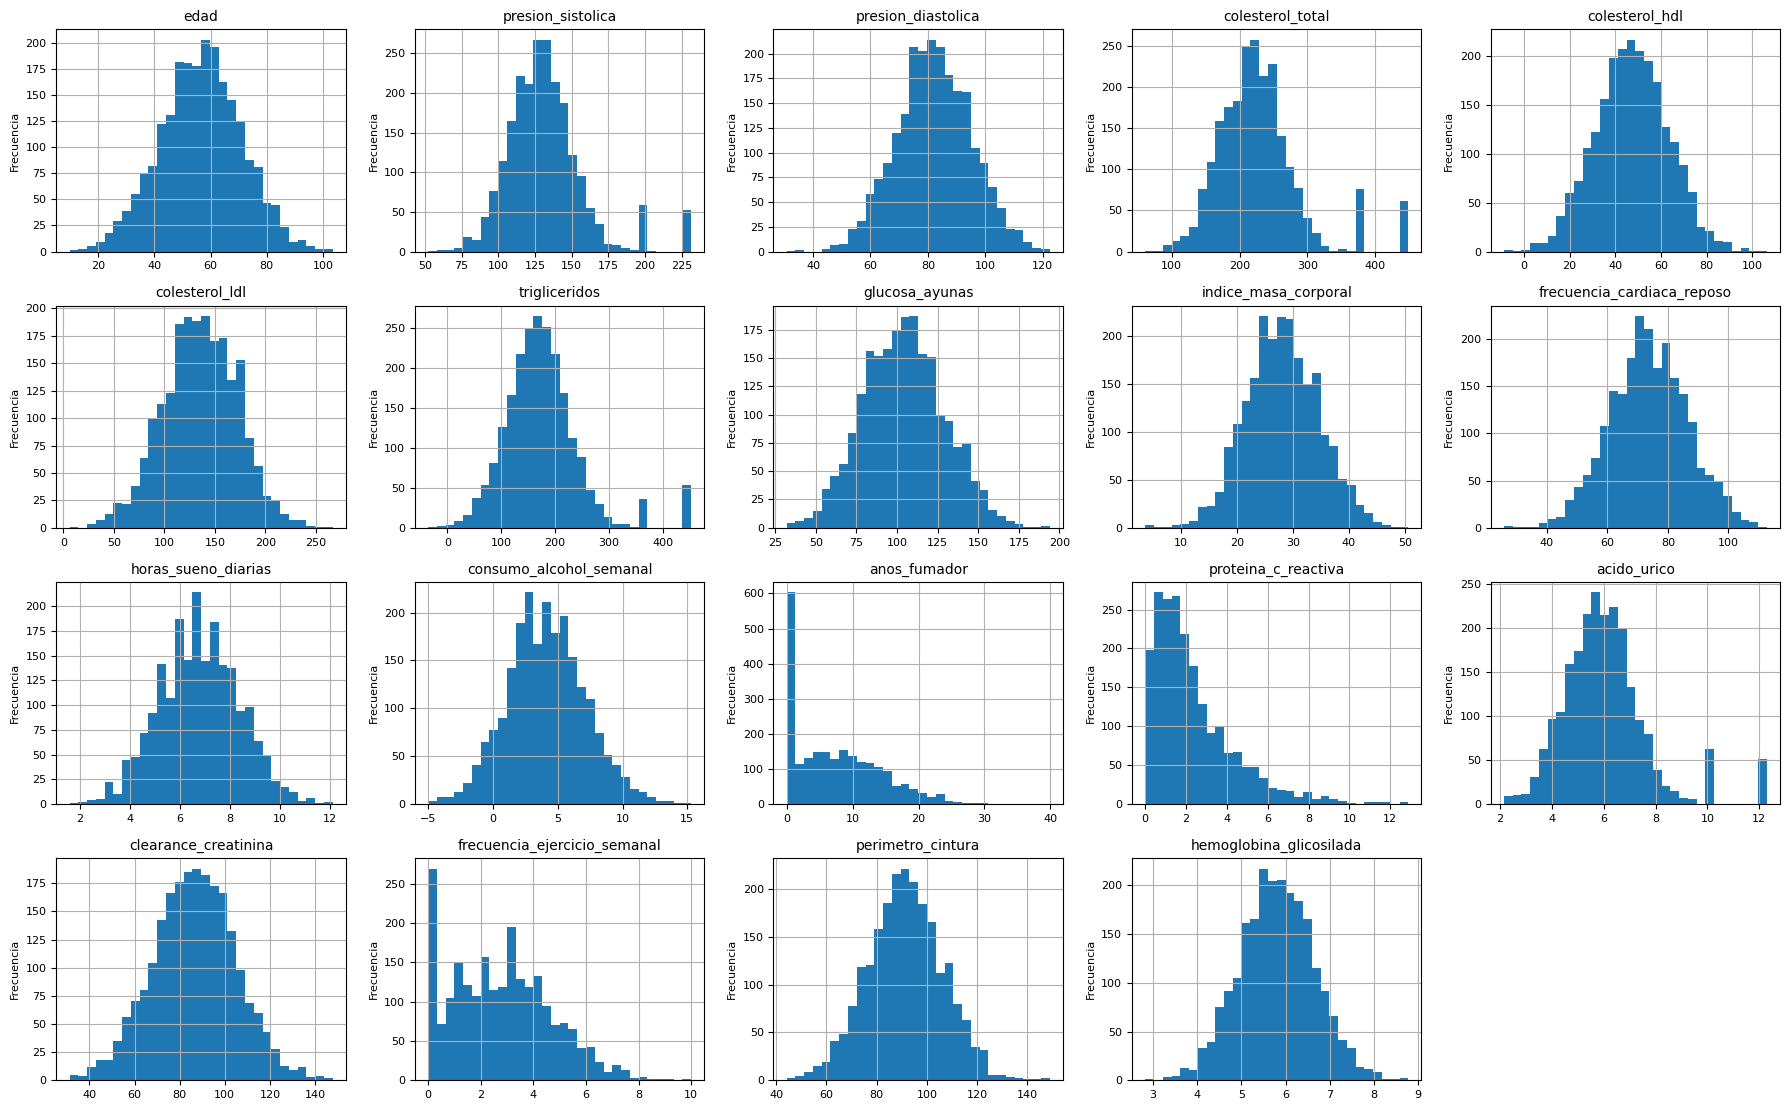

In [10]:
# Configuración de la cuadrícula
n_columnas = 5
n_filas = math.ceil(len(COLS_NUMERICAS) / n_columnas)

fig, axes = plt.subplots(
    nrows=n_filas,
    ncols=n_columnas,
    figsize=(18, n_filas * 2.8)
)

# Aplanar la matriz de ejes para recorrerla fácilmente
axes = axes.flatten()

# Generar los histogramas
for i, col in enumerate(COLS_NUMERICAS):
    df[col].hist(bins=30, ax=axes[i])

    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia", fontsize=8)
    axes[i].tick_params(labelsize=8)

# Ocultar los gráficos vacíos
for ax in axes[len(COLS_NUMERICAS):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

A partir de la visualización del histograma de las distribuciones, podemos indicar:
- La mayoría muestran una forma acampanada y simétrica: edad, presion_sistolica, presion_diastolica, colesterol_total, colesterol_hdl, colesterol_ldl, trigliceridos, glucosa_ayunas,indice_masa_corporal, frecuencia_cardiaca_reposo, horas_sueno_diarias, consumo_alcohol_semanal, acido_urico, clearance_creatinina, perimetro_cintura y hemoglobina_glicosilada.
- Se observa una **fuerte asimetría** en variables como anos_fumador, frecuencia_ejercicio_semanal y proteina_c_reactiva, donde la gran mayoría de los registros se concentran en valores bajos (o cero) y existe una cola larga hacia la derecha.

Tambien podemos observar que hay diferencias en las magnitudes y rangos de las variables, lo que invita a aplicar un proceso de normalización o estandarización mas adelante.

Además, hay variables con valores atípicos en algunas variables situados en sus extremos que deben ser evaluados para determinar si son errores.

Calculamos para cada variable numérica, sus valores más frecuentes.

In [11]:
for col in COLS_NUMERICAS:
    print(col, df[col].nunique(), df[col].value_counts().head(5).to_dict())

edad 607 {60.9: 12, 69.4: 12, 59.2: 11, 54.9: 11, 56.7: 11}
presion_sistolica 755 {196.95: 59, 231.36: 53, 133.7: 10, 129.8: 9, 122.6: 9}
presion_diastolica 571 {80.0: 12, 78.6: 12, 84.9: 12, 94.4: 12, 73.9: 11}
colesterol_total 1223 {371.24: 74, 448.59: 61, 242.2: 8, 247.6: 7, 195.0: 7}
colesterol_hdl 657 {46.3: 14, 48.8: 13, 44.8: 11, 51.6: 11, 47.9: 11}
colesterol_ldl 1105 {136.6: 7, 125.0: 7, 144.5: 6, 142.1: 6, 121.0: 6}
trigliceridos 1351 {452.7: 54, 357.56: 36, 177.6: 6, 170.2: 6, 189.2: 6}
glucosa_ayunas 872 {83.2: 9, 88.2: 9, 118.1: 8, 102.6: 8, 122.5: 8}
indice_masa_corporal 319 {25.0: 22, 26.1: 20, 24.9: 20, 26.0: 19, 27.9: 19}
frecuencia_cardiaca_reposo 565 {74.8: 14, 72.6: 14, 69.8: 13, 71.2: 12, 67.3: 12}
horas_sueno_diarias 92 {6.8: 64, 6.7: 58, 6.2: 53, 6.0: 52, 7.6: 51}
consumo_alcohol_semanal 167 {2.6: 47, 2.4: 43, 2.9: 37, 4.9: 36, 3.7: 36}
anos_fumador 260 {0.0: 503, 12.2: 17, 6.5: 17, 9.2: 16, 10.1: 16}
proteina_c_reactiva 619 {1.35: 13, 1.79: 13, 1.17: 12, 0.7: 11

De este cálculo llaman la atención las variables con valores atípicos ya vistos en la visualización de las distribuciones:
-  La variable `presion_sistolica` con algunos campos que se repiten mucho: tiene 755 valores distintos en 2254 (cada valor debería aparecer de media unas 3 veces). El primero (196.95) y el segundo valor (231.36, que además es el máximo) mas repetido aparecen 59 y 53 veces. Los siguientes valores se repiten, como mucho, 10 veces. Además, esos dos valores tienen 2 decimales mientras el resto solo tienen uno.
- Podemos observar un comportamiento análogo con las variables: `colesterol_total` y `trigliceridos`. 
- También tenemos el caso del `acido_urico`, donde los dos primeros se repiten muchas veces aunque aquí no ocurre lo del número de decimales.
- Por último, tenemos los casos de `anos_fumador` y `frecuencia_ejercicio_semanal`, donde el valor más repetido (0.0 en ambos) es mucho mayor que el resto de valores, aunque en estos casos hay muchos menos valores distintos y tiene sentido que esos valores aparezcan más que el resto.

Vamos a comprobar si los valores anómalos anteriores son valores introducidos por algún procedimiento.

#### A) Analizar frecuencias y precisión decimal

In [12]:
columna = "presion_sistolica"
valores_sospechosos = [196.95, 231.36]

serie = pd.to_numeric(df[columna], errors="coerce")

frecuencias = serie.value_counts()

print("Valores más frecuentes:")
display(frecuencias.head(15))

print("\nPorcentaje de registros sospechosos:")
print(f"{serie.isin(valores_sospechosos).mean():.2%}")

# Detectar valores que no coinciden con una décima.
# Se utiliza tolerancia para evitar errores de coma flotante.
dos_decimales = (
    serie.notna()
    & ~np.isclose(serie * 10, np.round(serie * 10))
)

print("\nRegistros que requieren más de un decimal:")
display(serie[dos_decimales].value_counts())

Valores más frecuentes:


presion_sistolica
196.95    59
231.36    53
133.70    10
129.80     9
122.60     9
112.10     9
113.60     9
131.00     9
133.30     9
120.70     8
126.00     8
140.70     8
129.20     8
115.70     8
128.30     8
Name: count, dtype: int64


Porcentaje de registros sospechosos:
4.97%

Registros que requieren más de un decimal:


presion_sistolica
196.95    59
231.36    53
Name: count, dtype: int64

In [18]:
# Variables y valores sospechosos
VARIABLES_SOSPECHOSAS = {
    "presion_sistolica": [196.95, 231.36],
    "colesterol_total": [371.24, 448.59],
    "trigliceridos": [452.7, 357.56],
    "acido_urico": [10.13, 12.29],
}

for columna, valores_sospechosos in VARIABLES_SOSPECHOSAS.items():

    serie = pd.to_numeric(df[columna], errors="coerce")
    frecuencias = serie.value_counts()

    print(f"\n{'=' * 65}")
    print(f"VARIABLE: {columna}")
    print(f"{'=' * 65}")

    # 1. Valores más frecuentes
    print("\nValores más frecuentes:")
    display(frecuencias.head(15).to_frame(name="Frecuencia"))

    # 2. Frecuencia de los valores sospechosos
    print("\nFrecuencia de los valores sospechosos:")
    display(
        frecuencias.reindex(
            valores_sospechosos,
            fill_value=0
        ).to_frame(name="Frecuencia")
    )

    # 3. Porcentaje de registros sospechosos
    mascara_sospechosos = serie.isin(valores_sospechosos)

    print("\nPorcentaje de registros sospechosos:")
    print(
        f"{mascara_sospechosos.sum()} de {len(serie)} registros "
        f"({mascara_sospechosos.mean():.2%})"
    )

    # 4. Detectar valores que requieren más de un decimal
    # Se utiliza tolerancia para evitar errores de coma flotante.
    dos_decimales = (
        serie.notna()
        & ~np.isclose(serie * 10, np.round(serie * 10))
    )

    print("\nValores con más de un decimal:")
    display(
        serie[dos_decimales]
        .value_counts()
        .to_frame(name="Frecuencia")
    )

    # 5. Comprobar si existen otros valores con más de un decimal
    otros_dos_decimales = (
        dos_decimales & ~mascara_sospechosos
    )

    print("\nOtros valores con más de un decimal:")
    print(
        f"{otros_dos_decimales.sum()} registros, "
        f"{serie[otros_dos_decimales].nunique()} valores distintos"
    )


VARIABLE: presion_sistolica

Valores más frecuentes:


,Frecuencia
presion_sistolica,
196.95,59
231.36,53
133.70,10
129.80,9
122.60,9
112.10,9
113.60,9
131.00,9
133.30,9



Frecuencia de los valores sospechosos:


,Frecuencia
presion_sistolica,
196.95,59
231.36,53



Porcentaje de registros sospechosos:
112 de 2254 registros (4.97%)

Valores con más de un decimal:


,Frecuencia
presion_sistolica,
196.95,59
231.36,53


... (15 outputs left out)

,Frecuencia
acido_urico,
10.13,61
12.29,51



Porcentaje de registros sospechosos:
112 de 2254 registros (4.97%)

Valores con más de un decimal:


,Frecuencia
acido_urico,
10.13,61
12.29,51
5.83,16
5.35,13
6.04,13
...,...
7.96,1
9.26,1
6.41,1



Otros valores con más de un decimal:
1930 registros, 491 valores distintos


#### B. Comparar los registros sospechosos con los demás

In [13]:
mascara = serie.isin(valores_sospechosos)

comparacion = pd.DataFrame({
    "Sospechosos": df.loc[mascara].select_dtypes(
        include="number"
    ).mean(),
    "Resto": df.loc[~mascara].select_dtypes(
        include="number"
    ).mean(),
})

comparacion["Diferencia"] = (
    comparacion["Sospechosos"]
    - comparacion["Resto"]
)

display(comparacion)

,Sospechosos,Resto,Diferencia
edad,56.705357,56.687395,0.017962
presion_sistolica,213.233304,128.084174,85.149130
presion_diastolica,81.626786,82.195798,-0.569013
colesterol_total,217.578750,228.685728,-11.106978
colesterol_hdl,45.970536,47.290803,-1.320267
colesterol_ldl,139.351852,135.439184,3.912667
trigliceridos,182.670357,176.342988,6.327369
glucosa_ayunas,107.874074,103.907325,3.966749
indice_masa_corporal,27.790179,28.109244,-0.319065
frecuencia_cardiaca_reposo,73.802679,73.661158,0.141521


Los registros sospechosos tienen una distribución de riesgo cardiovascular muy diferente, por lo que podrían estar introduciendo un patrón espurio en el modelo.

#### C. Visualizar las acumulaciones

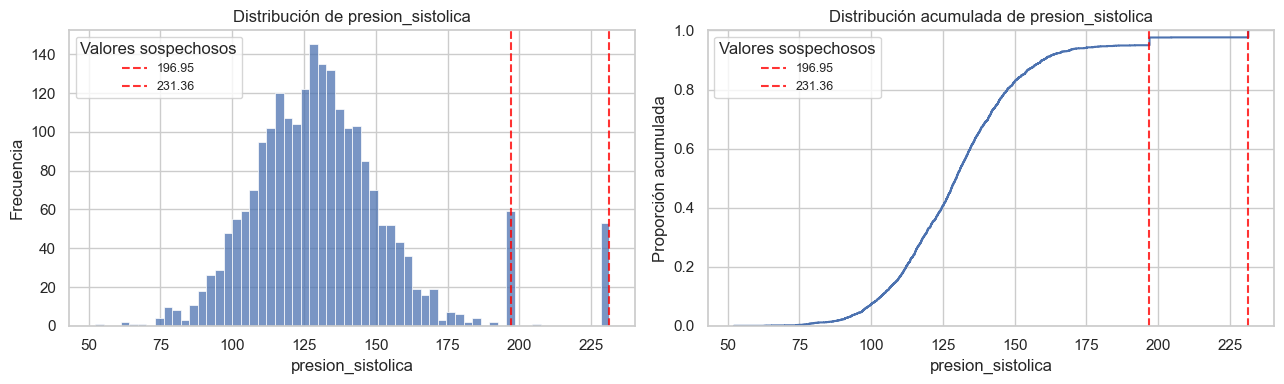

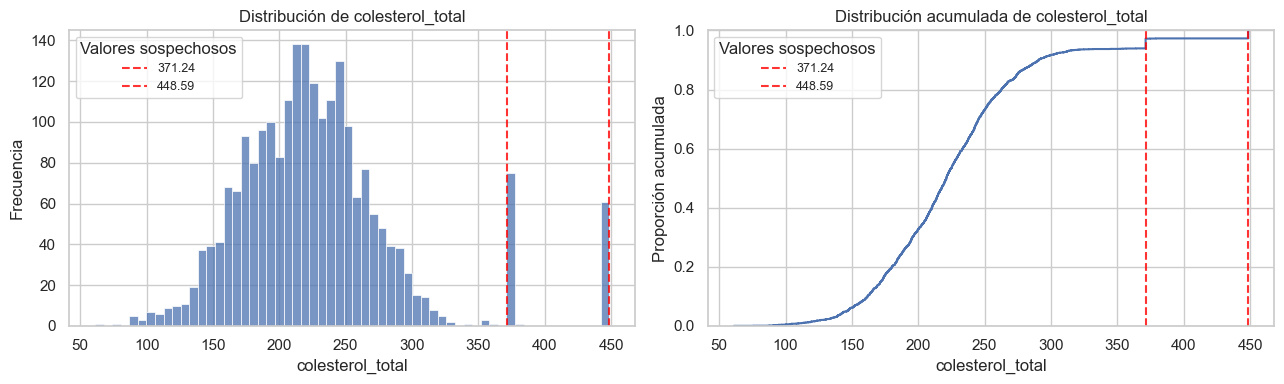

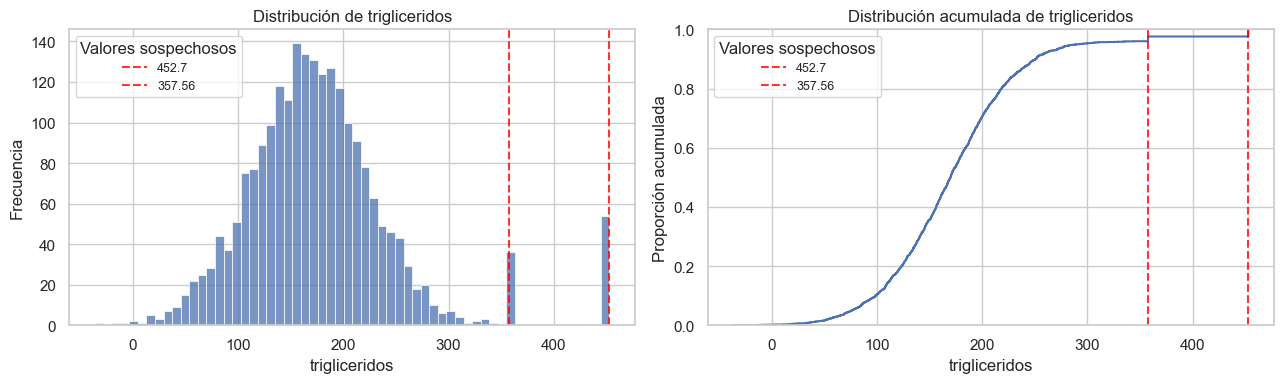

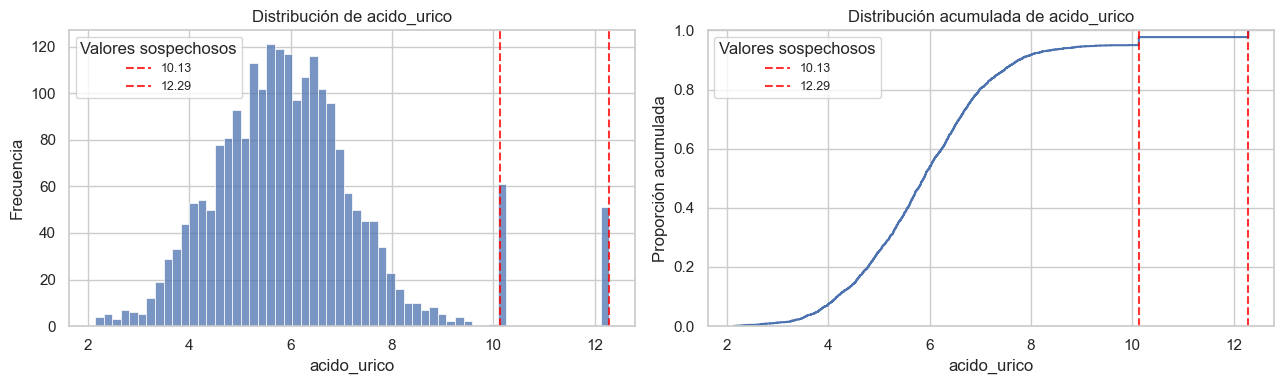

In [21]:
# Variables y valores sospechosos
VARIABLES_SOSPECHOSAS = {
    "presion_sistolica": [196.95, 231.36],
    "colesterol_total": [371.24, 448.59],
    "trigliceridos": [452.7, 357.56],
    "acido_urico": [10.13, 12.29],
}

sns.set_theme(style="whitegrid")

for columna, valores_sospechosos in VARIABLES_SOSPECHOSAS.items():

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # 1. Histograma de frecuencias
    sns.histplot(
        data=df,
        x=columna,
        bins=60,
        ax=axes[0]
    )

    # 2. Distribución acumulada (ECDF)
    sns.ecdfplot(
        data=df,
        x=columna,
        ax=axes[1]
    )

    # 3. Marcar los valores sospechosos
    for ax in axes:
        for valor in valores_sospechosos:
            ax.axvline(
                x=valor,
                color="red",
                linestyle="--",
                linewidth=1.5,
                alpha=0.8,
                label=str(valor)
            )

        ax.legend(title="Valores sospechosos", fontsize=9)
        ax.set_xlabel(columna)

    # 4. Títulos y etiquetas
    axes[0].set_title(f"Distribución de {columna}")
    axes[0].set_ylabel("Frecuencia")

    axes[1].set_title(f"Distribución acumulada de {columna}")
    axes[1].set_ylabel("Proporción acumulada")

    plt.tight_layout()
    plt.show()

En el histograma podemos ver claramente que hay picos aislados. En la distribución acumulada, encontramos saltos pronunciados exactamente en esos valores para las columnas analizadas.

### 3.2 Estudio de las variables booleanas y nominales

Para las variables booleanas comprobamos que solo toman 0 y 1. Para el caso de las nominales que solo contienen las categorías del enunciado, sin espacios sobrantes, mayúsculas distintas ni errores ortográficos. 

In [22]:
print('VARIABLES BOOLEANAS')
for col in COLS_BOOLEANAS:
    valores = df[col].unique().tolist()
    print(f'  {col:24s} valores = {valores}, % de 1s = {df[col].mean() * 100:.1f} %')

print('\nVARIABLES NOMINALES')
for col in COLS_NOMINALES:
    obtenidas = set(df[col].dropna().unique())
    print(f'  {col}: categorías obtenidas = {obtenidas}')
    print('   ', df[col].value_counts()) #, f'{col / df[col].value_counts() * 100:.1f %}')

print('\nVARIABLE OBJETIVO, valores:', sorted(df[TARGET].unique().tolist()))

VARIABLES BOOLEANAS
  fumador_actual           valores = [1, 0], % de 1s = 26.4 %
  hipertension_previa      valores = [1, 0], % de 1s = 36.7 %
  diabetes_mellitus        valores = [1, 0], % de 1s = 22.8 %
  tratamiento_estatinas    valores = [0, 1], % de 1s = 27.2 %
  uso_antihipertensivos    valores = [1, 0], % de 1s = 34.9 %

VARIABLES NOMINALES
  tipo_alimentacion: categorías obtenidas = {'Baja en carbohidratos', 'Occidental', 'Mediterránea', 'Vegetariana'}
    tipo_alimentacion
Occidental               881
Mediterránea             706
Baja en carbohidratos    349
Vegetariana              318
Name: count, dtype: int64
  nivel_actividad: categorías obtenidas = {'Sedentario', 'Moderadamente activo', 'Ligeramente activo', 'Muy activo'}
    nivel_actividad
Ligeramente activo      695
Sedentario              687
Moderadamente activo    563
Muy activo              309
Name: count, dtype: int64
  antecedentes_familiares_tipo: categorías obtenidas = {'Ambos', 'Paterno', 'Materno', 'Ninguno

Los dominios coinciden con lo indicado en el enunciado: booleanas en {0, 1}, nominales con sus cuatro categorías exactas y sin ausentes, y variable objetivo en {0, 1, 2}. Destacar que algunas categorías no están equilibradas.

### 3.3 Registros duplicados

In [23]:
print('Filas duplicadas:', df.duplicated().sum())

Filas duplicadas: 0


No hay duplicados

### 3.4 Valores ausentes (*missing*)

Antes de tomar ninguna decisión sobre qué hacer con los valores ausentes, hay que saber cuántos son, cómo se reparten y si la ausencia aporta información.

In [24]:
COLS_CON_NULOS = df.columns[df.isna().any()].tolist()

tabla_nulos = pd.DataFrame({
    'ausentes': df[COLS_CON_NULOS].isna().sum(),
    'porcentaje (%)': (df[COLS_CON_NULOS].isna().mean() * 100).round(2),
}).sort_values('ausentes', ascending=False)
display(tabla_nulos)

,ausentes,porcentaje (%)
horas_sueno_diarias,180,7.99
proteina_c_reactiva,157,6.97
colesterol_ldl,135,5.99
glucosa_ayunas,112,4.97


Podemos observar los siguientes valores missing:

1. Para la variable colesterol_ldl, faltan 135 registros.
2. Para la variable glucosa_ayunas tenemos 112 nulos.
3. La variable horas_sueno_diarias tiene 180 nulos.
4. La variable proteina_c_reactiva tiene 157 nulos.

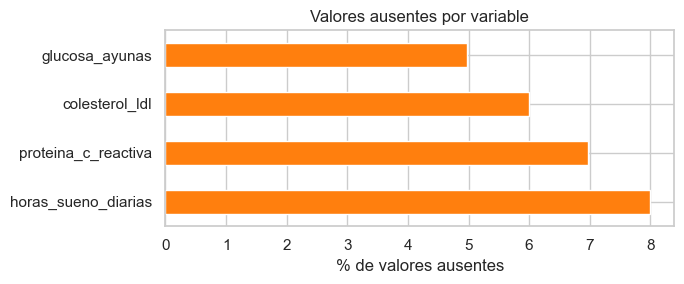

In [25]:
# Gráfico de barras con iformación de missing
fig, ax = plt.subplots(figsize=(7, 3))
tabla_nulos['porcentaje (%)'].plot.barh(ax=ax, color='tab:orange')
ax.set_xlabel('% de valores ausentes')
ax.set_title('Valores ausentes por variable')
plt.tight_layout()
plt.show()

Entre el 5 % y el 8 % de valores ausentes por variable. Parece un nivel bajo, lo que permite imputar.

La forma de tratar los ausentes depende de por qué faltan. Si faltan al azar, imputar no introduce sesgo. Si la ausencia depende de la clase o de otras variables, el propio hecho de faltar es información y convendría conservarlo (por ejemplo, con una variable indicadora). Lo comprobamos de tres formas: (1) porcentaje de ausentes por nivel de riesgo, con un contraste χ² de independencia; (2) si las ausencias de distintas variables coinciden en los mismos pacientes; (3) cuántos pacientes se perderían si se eliminaran las filas incompletas.

Para las variables que contienen tantos nulos, vamos a ver cómo se relacionan con la variable objetivo.

In [30]:
# El objetivo no debe tener ausentes: si los tuviera, hay que verlo.
assert df[TARGET].notna().all(), 'El objetivo tiene ausentes: revisar antes de continuar'

# Solo los predictores con ausentes (el objetivo queda fuera)
COLS_CON_NULOS = [c for c in df.columns if df[c].isna().any() and c != TARGET]

# (1) ¿La ausencia depende del nivel de riesgo?
filas = []
for col in COLS_CON_NULOS:
    falta = df[col].isna()
    pct_por_clase = falta.groupby(df[TARGET]).mean() * 100
    _, p_valor, _, _ = stats.chi2_contingency(pd.crosstab(falta, df[TARGET]))
    filas.append({
        'variable': col,
        '% ausentes riesgo 0': pct_por_clase[0],
        '% ausentes riesgo 1': pct_por_clase[1],
        '% ausentes riesgo 2': pct_por_clase[2],
        'p-valor (chi2)': p_valor,
    })
display(pd.DataFrame(filas).set_index('variable').round(3))

# (2) ¿Las ausencias coinciden en los mismos pacientes?
print('Correlación entre los indicadores de ausencia:')
display(df[COLS_CON_NULOS].isna().astype(int).corr().round(2))

# (3) ¿Cuántos pacientes tienen algún ausente?
nulos_por_fila = df[COLS_CON_NULOS].isna().sum(axis=1)
print('Pacientes según su número de ausentes:', nulos_por_fila.value_counts().sort_index().to_dict())
print(f'Pacientes con al menos un ausente: {(nulos_por_fila > 0).sum()} '
      f'({(nulos_por_fila > 0).mean() * 100:.1f} %)')
esperados_completos = np.prod(1 - df[COLS_CON_NULOS].isna().mean()) * len(df)
print(f'Pacientes completos: {(nulos_por_fila == 0).sum()} observados '
      f'frente a {esperados_completos:.0f} esperados si las ausencias fueran independientes')

,% ausentes riesgo 0,% ausentes riesgo 1,% ausentes riesgo 2,p-valor (chi2)
variable,,,,
colesterol_ldl,6.389,6.065,4.878,0.518
glucosa_ayunas,4.437,4.586,6.874,0.114
horas_sueno_diarias,8.252,7.692,7.761,0.896
proteina_c_reactiva,8.163,5.769,5.765,0.082


Correlación entre los indicadores de ausencia:


,colesterol_ldl,glucosa_ayunas,horas_sueno_diarias,proteina_c_reactiva
colesterol_ldl,1.00,-0.02,-0.03,0.03
glucosa_ayunas,-0.02,1.00,0.02,-0.01
horas_sueno_diarias,-0.03,0.02,1.00,-0.00
proteina_c_reactiva,0.03,-0.01,-0.00,1.00


Pacientes según su número de ausentes: {0: 1721, 1: 484, 2: 47, 3: 2}
Pacientes con al menos un ausente: 533 (23.6 %)
Pacientes completos: 1721 observados frente a 1724 esperados si las ausencias fueran independientes


- El porcentaje de ausentes es parecido en las tres clases de riesgo y ningún contraste χ² es significativo al 5 % (p entre 0,082 y 0,896). Las variables más cercanas a la significación son `proteina_c_reactiva` (8,2 % en riesgo bajo frente a 5,8 % en las otras dos; p = 0,082) y `glucosa_ayunas` (6,9 % en riesgo alto frente a 4,4–4,6 % en las otras dos; p = 0,114). Con cuatro contrastes, diferencias de este tamaño son compatibles con el azar.
- La correlación entre indicadores de ausencia es prácticamente nula (|r| ≤ 0,03) y hay 1.721 pacientes completos, casi exactamente los 1.724 que se esperarían si cada variable perdiera datos de forma independiente. Las ausencias no se agrupan.
- Aunque cada variable pierde solo entre el 5 % y el 8 %, las ausencias caen en pacientes distintos: 533 pacientes (23,6 %) tienen al menos un ausente. Eliminar esas filas supondría perder casi una cuarta parte del dataset.

Todo es compatible con un mecanismo MCAR: los contrastes no aportan evidencia de que la ausencia dependa del riesgo ni de otras ausencias (no se puede demostrar, solo no encontrar indicios en contra). 

Conclusión: se imputará en lugar de eliminar filas, y no hay indicios de que haga falta una variable indicadora de ausencia. El método de imputación (mediana, k-NN...) se decidirá posteriormente, solo con los datos de entrenamiento.

### 3.5 Validación automática con reglas

Para auditar el dataset de forma sistemática usamos `src/validador_datos_cardiovasculares_v1.py`, que implementa  tres niveles del estudio de validación. **No modificamos el DataFrame**: devuelve una tabla con cada incidencia (fila, variable, valor, gravedad, regla) y un resumen por regla.

Las gravedades son `ERROR` (imposible o inconsistente) y `REVISION` (posible pero sospechoso). Varias reglas del validador todavía **no están decididas** (por ejemplo, que la edad con decimales sea un error). Aquí se ejecuta tal cual para ver qué detecta.

In [31]:
# Validador (antes de las decisiones del EDA)
from src.validador_datos_cardiovasculares_v1 import validar_datos_cardiovasculares

incidencias, resumen_incidencias = validar_datos_cardiovasculares(df)

filas_error = incidencias.loc[incidencias['gravedad'] == 'ERROR', 'posicion'].nunique()
print(f'Incidencias totales: {len(incidencias)}')
print(f'Filas con al menos un ERROR: {filas_error} de {len(df)}')
resumen_incidencias


# Ruta de archivos de validacion
RUTA_VALIDACION = RAIZ / 'reports' / 'generated'
RUTA_VALIDACION.mkdir(parents=True, exist_ok=True)


# Guarda la tabla de incidencias y el resumen de una ejecución del validador
incidencias.to_csv(
    RUTA_VALIDACION / 'incidencias_validacion.csv', 
    index=False,
    encoding="utf-8-sig",
)
resumen_incidencias.to_csv(
    RUTA_VALIDACION / 'resumen_validacion.csv', 
    index=False,
    encoding="utf-8-sig",
)
print(f'Guardado en {RUTA_VALIDACION.relative_to(RAIZ)}: '
          f'incidencias_validacion.csv ({len(incidencias)} filas), resumen_validacion.csv')

Incidencias totales: 5347
Filas con al menos un ERROR: 2224 de 2254
Guardado en reports\generated: incidencias_validacion.csv (5347 filas), resumen_validacion.csv


Según el validador, **2.224 de los 2.254 pacientes (98,7 %) tienen algún error**. Es un porcentaje demasiado alto. Hay que revisar los resultados:

- **`EDAD_NO_ENTERA` (2.046) y `EJERCICIO_NO_ENTERO` (1.836).** Casi todos los valores de esas columnas tienen decimales. Cuando mas del 90 % de valores incumple una regla de formato, lo más probable es que la regla de formao no se ajuste a cómo se registró la variable. Lo contrario, que mas del 90 % sean errores, tiene poco sentido.
- **`SUEÑO_FUERA_RANGO` (180): es un falso positivo del validador.** Ningún valor de sueño está fuera de 0–24 h. Lo que ocurre es que esas incidencias son exactamente los 180 **ausentes** de la variable que hemos detectado anteriormente. 
- **`VALOR_NEGATIVO` (185):** 4 en HDL, 4 en triglicéridos y **177 en alcohol**.
- **Relaciones cruzadas:** 44 presiones con sistólica ≤ diastólica, 140 LDL mayores que el colesterol total y 559 LDL mayores que el colesterol no HDL.
- **`VALOR_CLINICO_EXTREMO` (188):** marcados para revisión, no son errores. Se tendrían que revisar caso a caso.

Actualizamos el validador para auditar el dataset de forma sistemática más profunda, usando `src/validador_datos_cardiovasculares_v2.py`, para que tenga en cuenta además la detección de valores extremos (mínimos y máximos) y de valores inválidos por definición o inconsistencias entre variables.

In [32]:
# Validador v2 (antes de las decisiones del EDA)
from src.validador_datos_cardiovasculares_v2 import validar_datos_cardiovasculares

#incidencias, resumen_incidencias = validar_datos_cardiovasculares(df)


incidencias, resumen = validar_datos_cardiovasculares(df)

print("=== RESUMEN DE INCIDENCIAS ===")
display(resumen)

print("\n=== DETALLE DE INCIDENCIAS ===")
display(incidencias)

print(f"\nRegistros analizados: {len(df)}")
print(f"Incidencias detectadas: {len(incidencias)}")
print(
    "Registros afectados:",
    incidencias["indice"].dropna().nunique(),
)


# Ruta de archivos de validacion
RUTA_VALIDACION = RAIZ / 'reports' / 'generated'
RUTA_VALIDACION.mkdir(parents=True, exist_ok=True)


# Guarda la tabla de incidencias y el resumen de una ejecución del validador
incidencias.to_csv(
    RUTA_VALIDACION / 'incidencias_validacion_v2.csv', 
    index=False,
    encoding="utf-8-sig",
)
resumen.to_csv(
    RUTA_VALIDACION / 'resumen_validacion_v2.csv', 
    index=False,
    encoding="utf-8-sig",
)
print(f'Guardado en {RUTA_VALIDACION.relative_to(RAIZ)}: '
          f'incidencias_validacion_v2.csv ({len(incidencias)} filas), resumen_validacion_v2.csv')

=== RESUMEN DE INCIDENCIAS ===


,variable,tipo,regla,casos
0,edad,INVALIDO,Edad no entera,2046
1,frecuencia_ejercicio_semanal,INVALIDO,Número de días no entero,1836
2,colesterol_ldl,INCONSISTENCIA,LDL > colesterol no-HDL,559
3,horas_sueno_diarias,INVALIDO,Valor ausente,180
4,consumo_alcohol_semanal,EXTREMO,Inferior al límite de plausibilidad,177
5,consumo_alcohol_semanal,INVALIDO,Valor negativo,177
6,proteina_c_reactiva,INVALIDO,Valor ausente,157
7,colesterol_ldl,INCONSISTENCIA,LDL > colesterol total,140
8,colesterol_ldl,INVALIDO,Valor ausente,135
9,presion_sistolica,ALERTA_CLINICA,Sistólica > 180 mmHg,121



=== DETALLE DE INCIDENCIAS ===


,indice,variable,valor,tipo,regla,detalle
0,1,colesterol_ldl,NaN,INVALIDO,Valor ausente,El registro no contiene un valor.
1,35,colesterol_ldl,NaN,INVALIDO,Valor ausente,El registro no contiene un valor.
2,39,colesterol_ldl,NaN,INVALIDO,Valor ausente,El registro no contiene un valor.
3,78,colesterol_ldl,NaN,INVALIDO,Valor ausente,El registro no contiene un valor.
4,88,colesterol_ldl,NaN,INVALIDO,Valor ausente,El registro no contiene un valor.
...,...,...,...,...,...,...
5938,1764,hemoglobina_glicosilada,3.95,ALERTA_CLINICA,HbA1c < 4 %,Valor clínicamente relevante; requiere revisión.
5939,1989,hemoglobina_glicosilada,3.85,ALERTA_CLINICA,HbA1c < 4 %,Valor clínicamente relevante; requiere revisión.
5940,2023,hemoglobina_glicosilada,3.74,ALERTA_CLINICA,HbA1c < 4 %,Valor clínicamente relevante; requiere revisión.
5941,2094,hemoglobina_glicosilada,3.83,ALERTA_CLINICA,HbA1c < 4 %,Valor clínicamente relevante; requiere revisión.



Registros analizados: 2254
Incidencias detectadas: 5943
Registros afectados: 2233
Guardado en reports\generated: incidencias_validacion_v2.csv (5943 filas), resumen_validacion_v2.csv


### 3.6 Análisis detallado de anomalías

#### 3.6.1 Valores negativos
Las variables 'colesterol_hdl', 'trigliceridos' y 'consumo_alcohol_semanal' tienen valores negativos. Hay que ver si son errores de captura o nulos camuflados.

In [33]:
print('Análisis de variables negativas:')
for col in ['colesterol_hdl', 'trigliceridos', 'consumo_alcohol_semanal']:
    negativos = df.loc[df[col] < 0, col]
    print(f'{col}: {len(negativos)} negativos ({len(negativos) / len(df) * 100:.1f} %)'
          f' | mín = {negativos.min()} ')

Análisis de variables negativas:
colesterol_hdl: 4 negativos (0.2 %) | mín = -8.8 
trigliceridos: 4 negativos (0.2 %) | mín = -35.7 
consumo_alcohol_semanal: 177 negativos (7.9 %) | mín = -5.0 


De lo anteior podems indicar que:
- colesterol_hdl y triglicéridos: Son pocos casos (4 y 4) y aislados (0,2 % en ambos). Se comportan como errores puntuales de captura.
- La variable consumo_alcohol_semanal tiene muchos casos (177) siendo un 7,9 %. No parecen errores al azar.

Estudiamos los datos de consumo semanal de alcohol.

In [34]:
# Consumo semanal de alcohol
alcohol = pd.to_numeric(
    df['consumo_alcohol_semanal'],
    errors='coerce'
)

# Definición de intervalos
cortes = [-np.inf, 0, 2, 4, 6, np.inf]
etiquetas = ['negativo', '0 a <2', '2 a <4', '4 a <6', '6 o más']

# Clasificación por intervalos
tramo = pd.cut(
    alcohol,
    bins=cortes,
    labels=etiquetas,
    right=False
)

# Crear subconjunto con consumo y clase de riesgo conocidos
base = pd.DataFrame({
    'tramo': tramo,
    TARGET: df[TARGET]
}).dropna()

# Número de pacientes por intervalo
pacientes = (
    base['tramo']
    .value_counts()
    .reindex(etiquetas, fill_value=0)
)

# Número de pacientes de cada clase de riesgo
conteos_riesgo = pd.crosstab(
    base['tramo'],
    base[TARGET]
).reindex(
    index=etiquetas,
    columns=[0, 1, 2],
    fill_value=0
)

# Porcentajes dentro de cada intervalo
porcentajes = (
    conteos_riesgo
    .div(conteos_riesgo.sum(axis=1).replace(0, np.nan), axis=0)
    * 100
)

# Tabla final
tabla_alcohol = pd.DataFrame({
    'Pacientes': pacientes,
    '% riesgo bajo': porcentajes[0],
    '% riesgo moderado': porcentajes[1],
    '% riesgo alto': porcentajes[2]
})

tabla_alcohol.index.name = 'Consumo semanal (UBE)'

tabla_alcohol

,Pacientes,% riesgo bajo,% riesgo moderado,% riesgo alto
Consumo semanal (UBE),,,,
negativo,177,82.485876,15.819209,1.694915
0 a <2,330,71.818182,22.424242,5.757576
2 a <4,600,54.666667,32.000000,13.333333
4 a <6,553,46.473779,33.453888,20.072333
6 o más,594,26.767677,33.164983,40.067340


Con los datos negativos de consumo_alcohol_semanal podemos:
- Convertirlos en `NaN` e imputar con la media o la mediana asignaría un consumo moderado a 177 pacientes que presentan mayoritariamente un bajo riesgo.
- Recortarlos a 0 (es decir, asignarlos al grupo que no consume alcohol) conserva el sentido clínico.

Hay que decidir si convertir valores negativos de consumo_alcohol_semanal en `NaN` o recortarlos a 0.

#### 3.6.2 Valores positivos pero fisiológicamente imposibles o muy improbables

Para diferenciar entre valores imposibles o muy improbables habría que contar con la opinión de un experto del campo. De entre todos los valores extremos, con nuestro conocimiento, solo pondríamos los siguientes límites de corte entre extremo raro e imposible:
- indice_masa_corporal o IMC: presenta valores que no corresponden a ningún adulto vivo. Aunque no existe un mínimo absoluto universal establecido por la OMS, los valores menores de 10 son extremadamente bajos y podrían considerarse errores.
- frecuencia_cardiaca_reposo: Valores de menos de 30 lpm en reposo se pueden considerar Bradicardia extrema y requieren atención urgente. Aunque podrían ser reales, son tan poco probables en un estudio como el del proyecto que podríamos considerarlos valores imposibles.
- perimetro_cintura:  Valores de menos de menos de 40 cm son extremadamente pequeños para un adulto.

In [35]:
# Umbrales
UMBRALES_FISIOLOGICOS = {
    'indice_masa_corporal': 10,
    'frecuencia_cardiaca_reposo': 30,
    'perimetro_cintura': 40,
}

filas = []
for col, umbral in UMBRALES_FISIOLOGICOS.items():
    bajo = df[col] < umbral
    filas.append({
        'variable': col,
        'umbral de revisión': umbral,
        'num por debajo': int(bajo.sum()),
        'num negativos': int((df[col] < 0).sum()),
        'valores más bajos': sorted(df[col].tolist()),
    })
pd.DataFrame(filas)

,variable,umbral de revisión,num por debajo,num negativos,valores más bajos
0,indice_masa_corporal,10,8,0,"[3.6, 4.9, 5.1, 6.4, 8.2, 8.3, 9.6, 9.7, 10.0,..."
1,frecuencia_cardiaca_reposo,30,2,0,"[25.8, 26.6, 30.7, 32.6, 34.5, 38.0, 38.5, 38...."
2,perimetro_cintura,40,0,0,"[44.2, 46.1, 48.0, 48.7, 48.8, 49.0, 52.7, 52...."


Utilizaremos IMC < 10 y FC < 30 como límites operativos de plausibilidad extrema. Entre nuestros datos de perimetro_cintura no hay valores < 40.

### 3.6.3 Edad y frecuencia_ejercicio_semanal con decimales

La edad parece estar registrada como variable continua, no en años cumplidos como dice el enunciado. Marcar 2046 registros como erróneos no tiene sentido. Hay que decidir es si se acepta como continua o se trunca a años cumplidos.

Algo parecido sucede con frecuencia_ejercicio_semanal, donde 1836 valores (81 %) indican el número de días como variable continua. Podría interpretarse como días por semana en promedio, y en ese caso los decimales tienen sentido.

### 3.6.4 Frecuencia_ejercicio_semanal con valores 0 y mayores que 7

Análisis de Frecuencia_ejercicio_semanal:
Valores > 7: 41  ->  [7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.2, 7.2, 7.2, 7.2, 7.2, 7.3, 7.3, 7.4, 7.4, 7.4, 7.4, 7.4, 7.5, 7.5, 7.5, 7.5, 7.5, 7.6, 7.6, 7.6, 7.8, 7.9, 7.9, 8.1, 8.1, 8.3, 8.3, 8.4, 8.5, 8.8, 9.0, 9.7, 10.0]
Valores = 0: 204


C:\Users\Kanenas\AppData\Local\Temp\ipykernel_17980\484872593.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


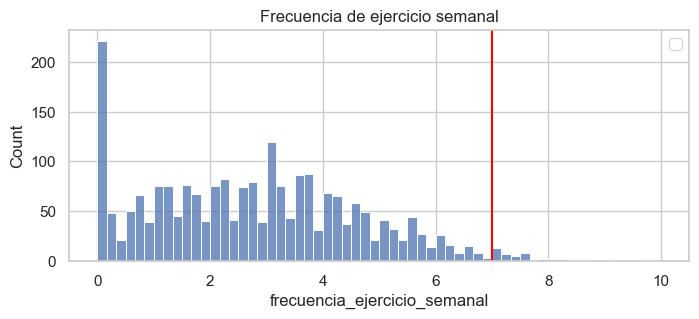

In [36]:
print('Análisis de Frecuencia_ejercicio_semanal:')
ejercicio = df['frecuencia_ejercicio_semanal']
print(f'Valores > 7: {(ejercicio > 7).sum()}  ->  {sorted(ejercicio[ejercicio > 7].tolist())}')
print(f'Valores = 0: {(ejercicio == 0).sum()}')

fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(ejercicio, bins=60, ax=ax)
ax.axvline(7, color='red')
ax.set_title('Frecuencia de ejercicio semanal')
ax.legend()
plt.show()

- 41 valores superan los 7 días de la semana. De ellos, la mayoría están entre 7,1 y 7,9.
- Hay un pico de 204 ceros al principio del histograma. Aquí el cero parece un valor válido y con sentido (no hace ejercicio).

#### 3.6.5 Valores repetidos en el extremo superior

Las variables `presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico` presentan, cada una, dos valores que se repiten decenas de veces mientras que el resto de valores no pasa de 10–16 repeticiones. Para decidir qué son comprobamos tres cosas: (1) dónde caen respecto al resto de la distribución; (2) si los pacientes que los tienen se parecen entre sí en el resto de variables; (3) si su nivel de riesgo difiere del general.

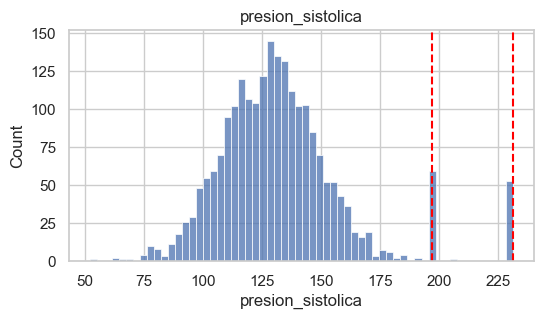

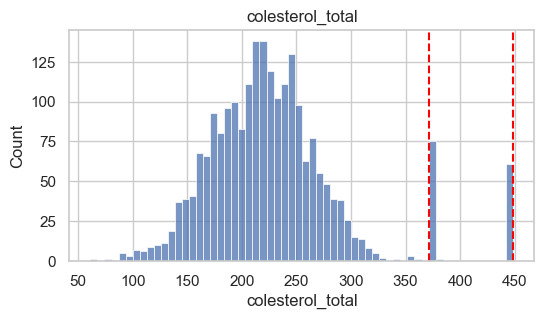

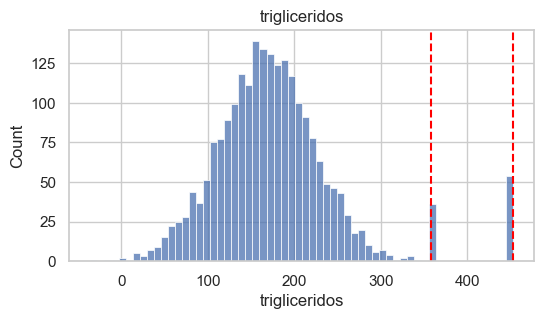

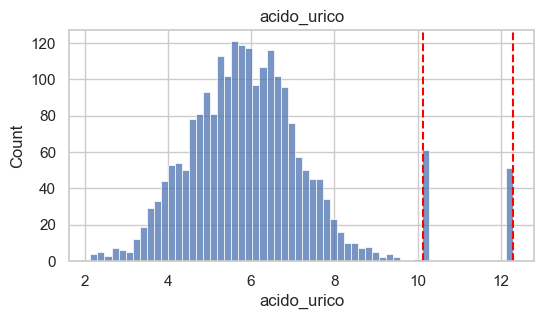

In [40]:
VALORES_REPETIDOS = ['presion_sistolica', 'colesterol_total', 'trigliceridos', 'acido_urico']

for col in VALORES_REPETIDOS:

    repetidos = (
        df[col]
        .value_counts()
        .loc[lambda x: x > 20]
        .index
    )

    plt.figure(figsize=(6,3))
    sns.histplot(df[col], bins=60)

    for valor in repetidos:
        plt.axvline(valor, color='red', ls='--')

    plt.title(col)
    plt.show()

A la derecha de cada distribución se ven claramente los picos aislados. Algo que no tiene una población real.

#### 3.6.6 Coherencia entre variables

Hay valores posibles por separado que juntos son incompatibles. Se revisan las relaciones que propone el estudio de validación.

**Presión arterial: la sistólica debe ser mayor que la diastólica.**

In [ ]:
pas, pad = df['presion_sistolica'], df['presion_diastolica']
incoherente = pas <= pad
print(f'Pacientes con sistólica <= diastólica: {incoherente.sum()} ({incoherente.mean() * 100:.1f} %)')
df.loc[incoherente, ['presion_sistolica', 'presion_diastolica']].describe().round(1).T

44 pacientes (2 %) tienen la sistólica igual o menor que la diastólica, lo que es fisiológicamente imposible.

**Tabaco: años de fumador frente a edad y frente a fumador actual.**

In [ ]:
fumador, anos, edad = df['fumador_actual'], df['anos_fumador'], df['edad']
print('Años de fumador > edad: ', (anos > edad).sum())
print('Empezó a fumar antes de los 10 años (edad - años < 10):', (edad - anos < 10).sum())
print('Fumador actual con 0 años de exposición: ', ((fumador == 1) & (anos == 0)).sum())
print('No fumador con años de exposición (exfumador):', ((fumador == 0) & (anos > 0)).sum())
pd.crosstab(df['fumador_actual'], df['anos_fumador'] == 0,
            rownames=['fumador_actual'], colnames=['anos_fumador = 0'])

- 1 paciente con más años fumando que años de vida (imposible) y 18 que habrían empezado a fumar antes de los 10 años. Entre estos últimos están los menores de 18 años.
- 123 fumadores actuales con 0 años de exposición: podría ser alguien que acaba de empezar (menos de un año). Es para revisar.
- 1.279 no fumadores con años de exposición: podrían se ex-fumadores.

### 3.7 Valores atípicos

El siguiente paso es comprobar cuántos valores outliers tenemos para cada variable.

In [ ]:
for c in df.columns:
    if df[c].dtype in ['int64', 'float64']:
        Q1 = df[c].quantile(0.25)
        Q3 = df[c].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = df[(df[c] < lower_bound) | (df[c] > upper_bound)]
        print(f"Variable: {c}, Outliers: {len(outliers)}")

Vamos a ver cómo se relacionan las variables con muchos outliers con la variable objetivo.

In [ ]:
import seaborn as sns

#variables_clave = ['diabetes_mellitus', 'acido_urico', 'proteina_c_reactiva', 'colesterol_total', 'presion_sistolica', 'trigliceridos', 'riesgo_cardiovascular']
variables_clave = ['acido_urico', 'proteina_c_reactiva', 'colesterol_total', 'presion_sistolica', 'trigliceridos', 'riesgo_cardiovascular']

sns.pairplot(df[variables_clave], hue="riesgo_cardiovascular", height = 2, palette = 'colorblind')

- diabetes_mellitus (Booleano): Diagnóstico previo de diabetes mellitus tipo 2 (1: Sí, 0: No).

Esta variable es la que contiene más outliers, pero en realidad, el error es provocado porque es un valor booleano, que solo puede tomar 0's o 1's. Vamos a cambiar el tipo de dato de la variable a booleano, para dejar de tener en cuenta esos "supuestos" valores outliers.

In [ ]:
df['diabetes_mellitus'] = df['diabetes_mellitus'].astype(bool)

In [ ]:
df['diabetes_mellitus'].dtypes

Para el resto de variables con muchos valores 'outliers', vamos a analizar sus valores, para sabe si se trata de errores, o si por el contrario, son pacientes con esos valores muy altos, pero dentro de la normalidad.

In [ ]:
# presion_sistolica, colesterol_total, trigliceridos, proteina_c_reactiva, acido_urico

df[variables_clave].agg(['min', 'max'])

1. acido_urico --> El valor máximo de 12.29 es fisiológicamente posible, por lo que no lo vamos a eliminar.

Rangos normales de referencia
- Hombres: 3.4 - 7.0 
- Mujeres: 2.4 - 6.0 
- Niños / Población pediátrica: 2.0 - 5.5 

2. proteína_c_reactiva --> El valor máximo de 12,88 se considera clínicamente posible, por ello, tampoco lo vamos a eliminar. La Proteína C Reactiva es un reactante de fase aguda que aumenta solo cuando hay procesos inflamatorios, infecciones o daño tisular. Un valor de 0 mg/L (o cercano a cero) indica ausencia de inflamación sistémica

3. colesterol_total --> También se consideran valores normales.

4. presion_sistolica --> Mantenemos los valores.

- Mínimo: 52.20
    - Evaluación: Es una cifra de hipotensión muy marcada (extrema), pero los valores en la cola inferior aumentan gradualmente (62.8, 63.5, 65.4, 70.0, etc.), representando pacientes con presión arterial muy baja.
- Máximo: 231.36 
    - Evaluación: Está truncado (Top-Coded). Al igual que el ácido úrico y el colesterol total, el valor exacto de 231.36 se repite en 53 pacientes diferentes, lo que confirma que las lecturas por encima de ese umbral se acotaron a 231.36.

5. trigliceridos

- Aquí sí tenemos un problema. El valor mínimo debe estar entre 30-40 y tenemos valores negativos.

- La solución que hemos decidido, es convertir los valores inferiores a 30 a nulos, y después imputarles la mediana. 

### 3.8 Distribución de las variables numéricas por nivel de riesgo

### 3.9 Relación de los predictores con el riesgo cardiovascular

#### Variables numéricas

#### Variables booleanas y nominales

### 3.10 Variable objetivo y desbalanceo

In [ ]:
conteo = df[TARGET].value_counts().sort_index()
porcentaje = df[TARGET].value_counts(normalize=True).sort_index() * 100
tabla_clases = pd.DataFrame({'pacientes': conteo, 'porcentaje (%)': porcentaje.round(2)})
tabla_clases.index = ['0 - bajo', '1 - moderado', '2 - alto']
display(tabla_clases)
print(f'Ratio de desbalanceo (mayoritaria / minoritaria): {conteo.max() / conteo.min():.2f}')

fig, ax = plt.subplots(figsize=(5, 3))
tabla_clases['pacientes'].plot.bar(ax=ax, rot=0, color=sns.color_palette('colorblind')[:3])
ax.set_title('Distribución de la variable objetivo')
plt.show()

- El reparto es 50 % / 30 % / 20 %, con un ratio de desbalanceo de 2,5 : 1. Parece un desbalanceo moderado. Se destaca:
  1. La clase minoritaria es la más importante clínicamente.** No detectar a un paciente de alto riesgo (falso negativo) significa no aplicarle la prevención que necesita.
  2. Paradoja de la exactitud: un modelo que diga siempre *riesgo bajo* acierta el 50 % sin aprender nada. La exactitud no servirá como métrica principal. Posiblemente harán falta métricas por clase o promediadas (sensibilidad, F1 macro, Kappa), con el modelo trivial como línea base.
- Habrá que decidir en el preprocesamiento y la validación:
  - particiones estratificadas, para mantener el 50/30/20 en entrenamiento, test y cada pliegue.
  - posible tratamiento del desbalanceo siempre solo en entrenamiento, dentro del pipeline.

### 3.11 Escalas de las variables

In [ ]:
escalas = df[COLS_NUMERICAS].agg(['min', 'max', 'std']).T
escalas['rango'] = escalas['max'] - escalas['min']
escalas.sort_values('rango', ascending=False).round(2)

Los rangos van de unas 6 unidades (HbA1c) a casi 490 (triglicéridos): diferencias de rango grandes. En los modelos basados en distancias (como k-NN) o en gradientes (regresión logística regularizada), las variables de rango grande dominarían a las pequeñas. Habrá que escalar dentro del pipeline (`StandardScaler` o `RobustScaler`), ajustando solo con entrenamiento.

## 4. Decisiones de limpieza de datos

| Problema | Decisión tomada | Justificación |
|---|---|---|
| Edad con decimales (91 %) | Aceptarla como variable continua | Es una convención del registro, no un error de cada paciente; los decimales aportan precisión |
| 4 menores de 18 años | Eliminar las 4 filas | Están fuera de la población definida en el enunciado y dos son absurdos (9,8 años con 12,6 años fumando), suponen el 0,2 % |
| Ejercicio con decimales y 41 valores > 7 | Aceptar decimales (promedio semanal) y recortar a 7 | Casi todos están entre 7,1 y 7,9: el valor real más probable es 7 |
| 177 negativos de alcohol | Recortar a 0 (= no bebe) | Son la cola baja de la variable (82 % de clase 0); el recorte tiene sentido y conserva el orden |
| Negativos de HDL/TG e implausibles (IMC < 10,	frecuencia_cardiaca < 30) | a NaN  | Son incompatibles con un adulto vivo |
| Valores repetidos (420 filas) | a NaN  | Parecen nulos camuflados |
| 44 casos con sistólica ≤ diastólica | Ambas presiones a NaN | No se puede saber cuál de las dos es errónea |
| Lípidos incoherentes | LDL > colesterol total, LDL a NaN (140) | LDL > total es imposible por definición |
| Tabaco incoherente | Años de fumador > edad, a NaN. | Es imposible |

Tabla de límites de plausibilidad (D5).** Se aplica al valor estrictamente menor que el límite.

| Variable | Valor no plausible | Justificación | Valores afectados |
|---|---|---|---|
| `colesterol_hdl`, `trigliceridos` | ≤ 0 | Una concentración no puede ser nula ni negativa | 4 y 4 |
| `indice_masa_corporal` | < 10 kg/m² | Cerca del límite de supervivencia en desnutrición extrema | 13 |
| `frecuencia_cardiaca_reposo` | < 30 lpm | Incompatible con una medida normal en reposo en consulta sin medidas de urgencia | 2 |
| `hemoglobina_glicosilada` | < 3,5 % | Muy por debajo del intervalo habitual (4–5,6 %) | 5 |
| `perimetro_cintura` | < 50 cm | Extremadamente pequeño para un adulto | 6 |

## 5. Limpieza basada en reglas 

In [ ]:
import numpy as np

# Umbral fisiológico mínimo para triglicéridos (40 mg/dL)
UMBRAL_MIN_TRIGLICERIDOS = 30.0

df['trigliceridos'] = df['trigliceridos'].apply(lambda x: np.nan if x < UMBRAL_MIN_TRIGLICERIDOS else x)

df['trigliceridos'].describe()

- Ahora se me genera la duda, de si deberíamos hacer lo que hemos hecho con los trigliceridos, para cualquier variable que tome valores "imposibles".

In [ ]:

variables_con_valores_negativos = ['colesterol_hdl', 'consumo_alcohol_semanal']
df[variables_con_valores_negativos].describe()

In [ ]:
import numpy as np
from sklearn.impute import SimpleImputer

# Umbral fisiológico mínimo para COLESTEROL HDL (20 mg/dL)
UMBRAL_MIN_COLESTEROL_HDL = 20.0
UMBRAL_MIN_CONSUMO_ALCOHOL_SEMANAL = 0.0

df['colesterol_hdl'] = df['colesterol_hdl'].apply(lambda x: np.nan if x < UMBRAL_MIN_COLESTEROL_HDL else x)
df['consumo_alcohol_semanal'] = df['consumo_alcohol_semanal'].apply(lambda x: np.nan if x < UMBRAL_MIN_CONSUMO_ALCOHOL_SEMANAL else x)

imputer = SimpleImputer(strategy='median')
df[variables_con_valores_negativos] = imputer.fit_transform(df[variables_con_valores_negativos])

df[variables_con_valores_negativos].describe()


Vamos a revisar si las clases de la variable objetivo están desbalanceadas.

In [ ]:
# Conteo absoluto de cada clase
conteo = df['riesgo_cardiovascular'].value_counts()

# Porcentaje relativo de cada clase
porcentaje = df['riesgo_cardiovascular'].value_counts(normalize=True) * 100

# Combinar en una tabla
df_desbalance = pd.DataFrame({'Cantidad': conteo, 'Porcentaje (%)': porcentaje})
print(df_desbalance)

Como se observa, las clases están desbalanceadas, ya que si por ejemplo, creamos un modelo que siempre diga SIEMPRE que hay un "riesgo bajo" de enfermedad cardiovascular, acertaría en el 50% de los casos.

El siguiente paso va a ser analizar los tipos de datos asociados a cada una de las variables.

In [ ]:
df.dtypes

Aquí podemos ver que hay 3 variables categóricas: tipo_alimentación, nivel_actividad y antecedentes_familiares_tipo. 

Habrá que decidir qué hacer con ellas, dummies o OneHotEncoding.

In [ ]:
# Vamos a ver los valores que almacenan las 3 variables categóricas.

variables = ['tipo_alimentacion','nivel_actividad','antecedentes_familiares_tipo']

for col in df[variables].columns:
    valores = df[col].unique()
    print(f"Columna: {col} ({len(valores)} valores distintos)")
    print(valores)
    print("-" * 40)

Vamos a convertir las variables categóricas en Dummies.

In [ ]:
categoricas = df.select_dtypes(include = ["object", "category"]).columns
# Mostramos las columnas extraídas
categoricas

In [ ]:
# No eliminamos ninguna de las opciones --> drop_first = False.
# Creamos una columna para los nulos --> dummy_na = True.
categoricas_Datos = pd.get_dummies(df[categoricas], drop_first = False, dummy_na = True)
# Mostramos la transformación de las variables categóricas en variables dummies
categoricas_Datos.head()

In [ ]:
df.drop(categoricas, axis = 1, inplace = True)
# Tras eliminar los atributos originales, concatenamos los nuevos atributos creados para las variables categóricas.
datos = pd.concat([df, categoricas_Datos], axis = 1)
# Mostramos como quedan los datos de nuevo.
datos.head()

Teníamos originalmente 28 columnas. Hemos eliminado las 3 originales y hemos añadido 5 (4 + nulos) más por cada variable categórica --> 28-3+16 = 41. Obtenemos 40 porque parece que no hay nadie con dieta baja en carbohidratos.

In [ ]:
# Hacemos de nuevo dtype() para ver cuál es el estado actual.

datos.dtypes

Ahora ya solo tenemos variables int, float y booleanos.

In [ ]:
#(Clase 0: Bajo Riesgo, Clase 1: Riesgo Moderado y Clase 2: Alto Riesgo)

# Elegimos 3 variables para evitar que el gráfico sea inmanejable.
import seaborn as sns

variables_clave = ['edad', 'presion_sistolica', 'colesterol_total', 'riesgo_cardiovascular']

sns.pairplot(df[variables_clave], hue="riesgo_cardiovascular", height = 2, palette = 'colorblind')


El siguiente paso va a ser ejecutar bloxpot() para analizar la dispersión de los datos.

In [ ]:
import seaborn as sns

plt.figure(figsize=(14, 16))
sns.boxplot(data=datos, orient='h')
plt.tight_layout()
plt.show()


Analizando el gráfico encontramos rápidamente dos situaciones: 

1. Hay mucha diferencia en los rangos de valores entre algunas variables. Esto nos obligará a normalizar.

In [ ]:
# Importamos la clase StandardScaler para realizar el escalado
from sklearn.preprocessing import StandardScaler
# Importamos la clase LinearSVC
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split

# Instanciamos el escalador
scaler = StandardScaler()

In [ ]:
X=datos.drop(columns=["riesgo_cardiovascular"])
y=datos["riesgo_cardiovascular"]
X_train, X_test, y_train, y_test = train_test_split(X,y , test_size=0.2,random_state=0)

X_ent_escaladas = pd.DataFrame(scaler.fit_transform(X_train),columns=X_train.columns)

X_test_escaladas = pd.DataFrame(scaler.transform(X_test),columns=X_test.columns)

print(X_ent_escaladas)

# ¿¿Funcionaaa??? ¿¿Puedo visualizar algo??
#X_ent_escaladas.boxplot()

In [ ]:
plt.figure(figsize=(14, 16))
sns.boxplot(data=X_ent_escaladas, orient='h')
plt.tight_layout()
plt.show()

Hemos conseguido que todas las variables estén entre en el rango [-4,4], aunque aún vemos que hay valores outlier.